# Part 2: vulnerable vs fixed code

For every pair where **both** `original_code` (vulnerable) and `fixed_code` were measured, did the fix raise, keep
or lower each metric? Data and measuring as in Part 1 (`measure_snippets.py`).

One value per snippet:
- cyclomatic, cognitive, params, function SLOC: the snippet's **worst (max) function**; only pairs where both
  versions hold at least one function.
- snippet SLOC (every pair), comment density (pairs with at least one line in both), duplicated blocks.

In [1]:
import sys
from collections import Counter
from fractions import Fraction
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

HERE = Path.cwd()  # this notebook's folder: 05_derive_threshold/security
sys.path.insert(0, str(HERE.parent / "scripts"))
RESULTS, FIGURES = HERE / "results", HERE / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

if not (RESULTS / "snippets.csv").exists():  # measure once (about 40 s); delete the CSVs to re-measure
    import measure_snippets
    measure_snippets.main()
snippets = pd.read_csv(RESULTS / "snippets.csv")
functions = pd.read_csv(RESULTS / "functions.csv")
LANGS = ["python", "javascript", "typescript"]

# Chart style (light surface, reference data-viz palette; colors validated for color-blind separation)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
LANG_COLOR = {"python": "#2a78d6", "javascript": "#eb6834", "typescript": "#1baf7a"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.6, "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "legend.frameon": False,
})

In [2]:
import json

import measure_snippets

METRICS = {"cyclomatic": "Cyclomatic (max fn)", "cognitive": "Cognitive (max fn)", "params": "Params (max fn)",
           "function_sloc": "Function SLOC (max fn)", "snippet_sloc": "Snippet SLOC",
           "comment_density": "Comment density", "duplicated_blocks": "Duplicated blocks"}

m = snippets[snippets.status == "measured"].copy()
lines = m.sloc + m.cloc
m["comment_density"] = (100 * m.cloc / lines).where(lines > 0)
worst = functions.groupby(["sample_id", "version"]).agg(
    cyclomatic=("cyclomatic", "max"), cognitive=("cognitive", "max"),
    params=("params", "max"), function_sloc=("sloc", "max")).reset_index()
m = m.merge(worst, on=["sample_id", "version"], how="left").rename(columns={"sloc": "snippet_sloc"})

wide = m.pivot(index="sample_id", columns="version", values=list(METRICS))
info = m.drop_duplicates("sample_id").set_index("sample_id")[["language", "source", "cwe_id"]]
long = []
for metric in METRICS:
    pair = wide[metric].dropna()  # both versions have a value
    long.append(info.loc[pair.index].assign(metric=metric, vulnerable=pair.vulnerable, fixed=pair.fixed))
changes = pd.concat(long).reset_index()
diff = changes.fixed - changes.vulnerable
changes["change"] = pd.cut(diff, [-float("inf"), -1e-9, 1e-9, float("inf")], labels=["lower", "same", "higher"])
# raw dataset code (label comments kept), so each row can be read next to its numbers
code = pd.DataFrame(measure_snippets.load(measure_snippets.DEFAULT_DATA)).set_index("sample_id")[["original_code", "fixed_code"]]
changes.join(code, on="sample_id")[["sample_id", "language", "source", "cwe_id", "original_code", "fixed_code",
                                     "metric", "vulnerable", "fixed", "change"]].to_csv(
    RESULTS / "pair_changes.csv", index=False, lineterminator="\n")
# same data for reading: one object per pair; code as a list of lines so each line shows on its own row
pairs = [{"sample_id": sid, **g.iloc[0][["language", "source", "cwe_id"]].to_dict(),
          **{k: (v or "").splitlines() for k, v in code.loc[sid].items()},
          "metrics": {r.metric: {"vulnerable": r.vulnerable, "fixed": r.fixed, "change": r.change} for r in g.itertuples()}}
         for sid, g in changes.groupby("sample_id", sort=False)]
(RESULTS / "pair_changes.json").write_text(json.dumps(pairs, indent=2, ensure_ascii=False), encoding="utf-8")
both = m.groupby("sample_id").size().eq(2).sum()
print(f"{both} pairs with both versions measured")

437 pairs with both versions measured


## Change after the fix

Share of pairs where the fixed version is lower, the same, or higher than the vulnerable version.

In [3]:
def summary(df):
    pct = df.change.value_counts(normalize=True).reindex(["lower", "same", "higher"]).fillna(0) * 100
    return pd.Series({"pairs": len(df), "lower %": pct.lower, "same %": pct.same, "higher %": pct.higher,
                      "median vulnerable": df.vulnerable.median(), "median fixed": df.fixed.median()})


table = pd.concat([changes.groupby(["metric", "language"], sort=False).apply(summary),
                   changes.assign(language="all").groupby(["metric", "language"], sort=False).apply(summary)])
table = table.reindex(pd.MultiIndex.from_product([list(METRICS), LANGS + ["all"]])).dropna(how="all")
table.style.format({"pairs": "{:.0f}", "lower %": "{:.1f}", "same %": "{:.1f}", "higher %": "{:.1f}",
                    "median vulnerable": "{:.1f}", "median fixed": "{:.1f}"})

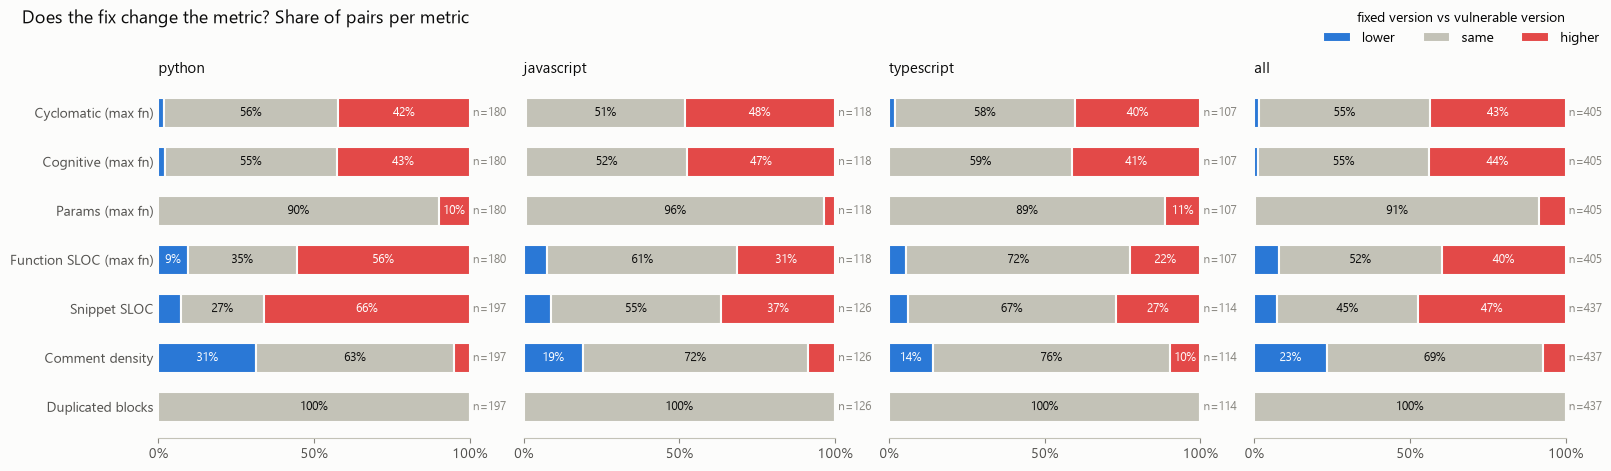

In [4]:
# Diverging colors: lower = blue, same = neutral gray, higher = red (direction only, not good/bad)
CHANGE_COLOR = {"lower": "#2a78d6", "same": "#c3c2b7", "higher": "#e34948"}
LABEL_INK = {"lower": "#ffffff", "same": INK, "higher": "#ffffff"}
panels = LANGS + ["all"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6), sharey=True, layout="constrained")
names = list(METRICS)
for ax, lang in zip(axes, panels):
    ax.grid(False)
    for y, metric in enumerate(names):
        if (metric, lang) not in table.index:
            continue
        row, left = table.loc[(metric, lang)], 0
        for change in ("lower", "same", "higher"):
            w = row[f"{change} %"]
            ax.barh(y, w, left=left, height=0.62, color=CHANGE_COLOR[change], edgecolor=SURFACE, linewidth=1.5,
                    label=change if (lang, y) == ("python", 0) else None)
            if w >= 9:
                ax.text(left + w / 2, y, f"{w:.0f}%", ha="center", va="center", fontsize=8.5, color=LABEL_INK[change])
            left += w
        ax.text(101, y, f"n={row.pairs:.0f}", va="center", fontsize=8.5, color=MUTED)
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 50, 100], ["0%", "50%", "100%"])
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(lang, loc="left")
axes[0].set_yticks(range(len(names)), [METRICS[n] for n in names])
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper right", ncols=3,
           title="fixed version vs vulnerable version")
fig.suptitle("Does the fix change the metric? Share of pairs per metric", x=0.01, ha="left", fontsize=13, color=INK)
fig.savefig(FIGURES / "part2_change_after_fix.png", dpi=150)
plt.show()